 # Adsorption Behavior of Trivalent Arsenic on Manganese Ferrite Nanoparticles: Kinetics, Isotherms, and Rate-Limiting Steps

**Authors:** López‑Luna, J.$^{1*}$, Vázquez-Hipólito, V.$^{2}$, Ramírez‑Montes, L.E.$^{3}$, Martinez‑Vargas, S.$^{4}$, Martínez, I.A.$^{5}$, Mijangos‑Ricardez, O.F.$^{3}$, Solís‑Domínguez, F.A.$^{6}$, Cuevas‑Díaz, M.C.$^{7}$

***

$^{1}$ Independent Researcher; $^{2}$ Universidad Tecnológica de la Mixteca, Oaxaca, México; $^{3}$ Universidad de la Sierra Juárez, Oaxaca, México;
$^{4}$ Universidad Autónoma del Carmen, Campeche, México; $^{5}$ Cinvestav-Saltillo, Coahuila, México; $^{6}$ Universidad Autónoma de Baja California, Baja California, México; $^{7}$ Universidad Veracruzana, Veracruz, México.

$^{*}$ **Corresponding author:** jlol_24@hotmail.com


https://doi.org/10.5281/zenodo.22695744
---

### Methodological Context & Source Code Evolution
The core experimental framework, raw datasets, and primary kinetic models utilized as the baseline for this project were originally published in:

*   **López-Luna, J., Ramírez-Montes, L.E., Martinez-Vargas, S. et al. Linear and nonlinear kinetic and isotherm adsorption models for arsenic removal by manganese ferrite nanoparticles. SN Appl. Sci. 1, 950 (2019). https://doi.org/10.1007/s42452-019-0977-3

The specific variants of the kinetic equations (IPD, PFO, PSO, Elovich) and the baseline equilibrium isotherms (**Freundlich and Langmuir**) applied herein are fully detailed and cited within the methodology of **López-Luna et al. (2019)**. 

In our original 2019 study, numerical optimization constraints within the closed-source MATLAB environment only achieved mathematical convergence for the Freundlich and Langmuir models. To overcome this limitation and expand the thermodynamic evaluation of surface energy heterogeneities, this updated open-source Python architecture achieves successful non-linear convergence for three additional equilibrium formulations:
*   **Temkin Isotherm** (https://doi.org/10.1016/j.cej.2009.09.013)
*   **Redlich–Peterson Isotherm** (https://doi.org/10.1016/j.cej.2009.09.013) 
*   **Toth Isotherm** (https://doi.org/10.1016/j.cej.2009.09.013)

---

## Experimental System Design Overview
This interactive notebook executes non-linear optimization algorithms to profile As(III) adsorption onto manganese ferrite nanoparticles ($MnFe_2O_4$) under controlled batch operations based on our 2019 published matrices:

1. **Adsorption Kinetics & Mass Transfer:** Tracks time-dependent concentrations ($C_0$ = 2, 5, 10, 20, and 40 mg/L; adsorbent dosage: 0.4 g/L; pH 2.0; room temperature) to resolve film diffusion boundaries and global rate parameters for manganese ferrite nanoparticles ($MnFe_2O_4$).

2. **Adsorption Isotherms & Equilibrium Profiles:** Characterizes concentration-dependent residual data at absolute thermal equilibrium using non-linear regressions to map surface energy heterogeneities.

## Aim of the Notebook
Transitioning our original 2019 modeling architecture into a completely open-source Python environment (`SciPy` & `Pandas`) to expand model coverage, eliminate linearization parameter distortions, and introduce the second-order Small-Sample Corrected Akaike Information Criterion (AICc) for robust parsimony selection.

---

## Repository File Registry
To ensure complete analytical traceability and reproducibility, this Zenodo software package is composed of the following official unified files:
*   **Interactive Core Engine:** `Arsenic_Adsorption_Notebook.ipynb` (The interactive Jupyter Notebook comprising multi-stage Weber-Morris pore diffusion modeling, non-linear kinetic parameterization [PFO, PSO, and Elovich], multi-model equilibrium isotherm optimization [Freundlich, Langmuir, Temkin, Redlich-Peterson, and Toth], and information-theoretic parsimony selection via AICc).
*   **Unified Analytical Engine:** `Ads_kinetics_As(III)_ferrite.py` (The unified Python script comprising multi-stage Weber-Morris pore diffusion modeling, non-linear kinetic parameterization [PFO, PSO, and Elovich], multi-model equilibrium isotherm optimization [Freundlich, Langmuir, Temkin, Redlich-Peterson, and Toth], and information-theoretic parsimony selection via AICc).
*   **Kinetic Raw Data Matrix:** `ads_over_time.csv` (Time-dependent adsorption records from 2 to 40 mg/L).
*   **Equilibrium Raw Data Matrix:** `dataeq.csv` (\(C_e\) vs. \(q_e\) residual equilibrium records).
*   **Technical User Manual:** `README.md` (Markdown documentation tracking operational parameters and dependencies).


<h2>2. Multi-Stage Weber-Morris Intraparticle Diffusion Model (IPD)</h2>

<p>In adsorption process modeling, mass transfer dynamics dictate that diffusion tracking must be evaluated first to identify step-limiting controls before quantifying global operational rates.</p>

<p style="text-align: center; font-size: 1.3em; margin: 20px 0; font-family: 'Times New Roman', Times, serif;">
  <b><i>q<sub>t</sub></i> = <i>k<sub>id</sub></i> · <i>t</i><sup>1/2</sup> + <i>C</i></b>
</p>

<p>Where:</p>
<ul>
  <li><b><i>q<sub>t</sub></i></b> is the adsorption capacity over time (mg/g).</li>
  <li><b><i>k<sub>id</sub></i></b> is the intraparticle diffusion rate constant (mg/g·min<sup>1/2</sup>).</li>
  <li><b><i>t</i><sup>1/2</sup></b> is the square root of contact time (min<sup>1/2</sup>).</li>
  <li><b><i>C</i></b> is an indicator of the boundary layer thickness (mg/g).</li>
</ul>

<p><b>Methodological Optimization Note:</b> To eliminate geometric parameter distortions on the plotting canvas, the experimental time matrix is explicitly transformed into its square root vector prior to executing the non-linear least-squares optimization (<code>curve_fit</code>).</p>

<p>Stage 1 (solid line) models the rapid external boundary layer film resistance, while Stage 2 (dashed line) quantifies the subsequent internal intraparticle pore diffusion controlling Arsenic [As(III)] transport into the <b>MnFe<sub>2</sub>O<sub>4</sub></b> nanoparticles.</p>



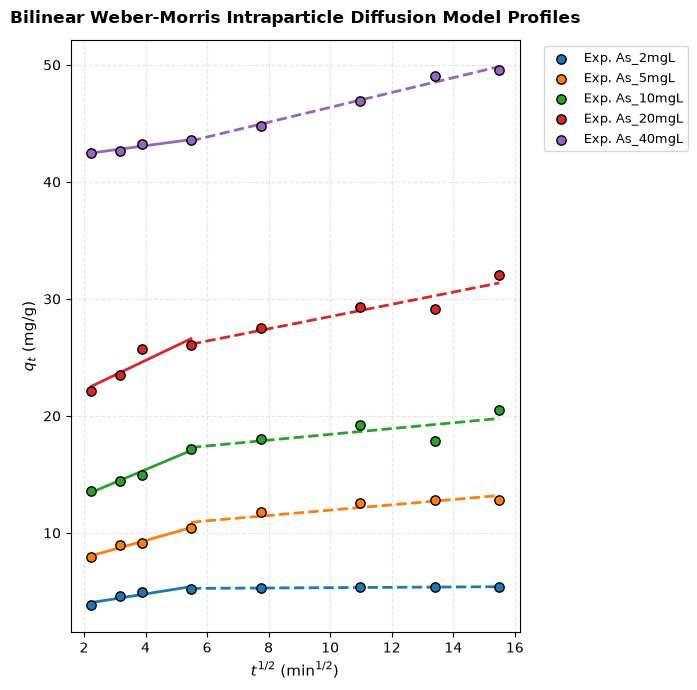


 WEBER-MORRIS INTROPARTICLE DIFFUSION MULTI-STAGE PARAMETER REPORT
AS_2MGL:
  Stage 1 (Boundary Film)  -> kid = 0.4200 mg/g·min^0.5 | C = 3.1064 mg/g
  Stage 2 (Pore Diffusion) -> kid = 0.0145 mg/g·min^0.5 | C = 5.1776 mg/g
...............................................................................................
AS_5MGL:
  Stage 1 (Boundary Film)  -> kid = 0.7419 mg/g·min^0.5 | C = 6.3871 mg/g
  Stage 2 (Pore Diffusion) -> kid = 0.2278 mg/g·min^0.5 | C = 9.6695 mg/g
...............................................................................................
AS_10MGL:
  Stage 1 (Boundary Film)  -> kid = 1.1053 mg/g·min^0.5 | C = 10.9872 mg/g
  Stage 2 (Pore Diffusion) -> kid = 0.2473 mg/g·min^0.5 | C = 15.9521 mg/g
...............................................................................................
AS_20MGL:
  Stage 1 (Boundary Film)  -> kid = 1.2589 mg/g·min^0.5 | C = 19.7059 mg/g
  Stage 2 (Pore Diffusion) -> kid = 0.5229 mg/g·min^0.5 | C = 23.2648 mg/g
..........

In [8]:
# ==============================================================================
# 2. MULTI-STAGE WEBER-MORRIS INTRAPARTICLE DIFFUSION MODEL (IPD)
# ==============================================================================
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
import pandas as pd

# The mathematical definition must receive the transformed square root of time directly
def ipd_linear_model(t_sqrt, kid, C):
    """
    t_sqrt: Transformed square root of time (min^0.5)
    kid: Intraparticle diffusion rate constant (mg/g·min^0.5)
    C: Boundary layer thickness indicator (mg/g)
    """
    return kid * t_sqrt + C

# Experimental kinetic data from Lopez-Luna et al. (2019)
# Bypassing the dictionary bracket bug with list functions
time_values = list([5, 10, 15, 30, 60, 120, 180, 240])

data = {
    "t": time_values,
    "As_2mgL": [3.82, 4.60, 4.95, 5.25, 5.29, 5.35, 5.38, 5.39],
    "As_5mgL": [7.91, 9.00, 9.15, 10.43, 11.83, 12.53, 12.80, 12.85],
    "As_10mgL": [13.61, 14.47, 14.98, 17.19, 18.07, 19.21, 17.88, 20.54],
    "As_20mgL": [22.10, 23.48, 25.73, 26.08, 27.50, 29.30, 29.15, 32.05],
    "As_40mgL": [42.48, 42.63, 43.28, 43.55, 44.80, 46.90, 49.05, 49.53]
}
df = pd.DataFrame(data)

params_dict = {}
plt.figure(figsize=(7, 7)) # Professional square aspect ratio for mechanism visualization

# Isolate experimental time matrix and transform to square root
t_experimental = df["t"].values
t_sqrt_global = np.sqrt(t_experimental)

for col in df.columns[1:]:  # Skip the time column 't'
    qt = df[col].values
    
    # Segment 1: Boundary Layer Film Diffusion (First 4 points)
    t1_sqrt, qt1 = t_sqrt_global[:4], qt[:4]
    params1, _ = curve_fit(ipd_linear_model, t1_sqrt, qt1, p0=[1.0, 1.0])
    kid1, C1 = params1
    
    # Segment 2: Intraparticle Pore Diffusion (Remaining points)
    t2_sqrt, qt2 = t_sqrt_global[3:], qt[3:] # Overlapping point 4 ensures geometric continuity
    params2, _ = curve_fit(ipd_linear_model, t2_sqrt, qt2, p0=[0.1, max(qt1)])
    kid2, C2 = params2
    
    params_dict[col] = {"stage1": (kid1, C1), "stage2": (kid2, C2)}
    
    # Continuous vector simulation for plot rendering
    t1_sim = np.linspace(min(t1_sqrt), max(t1_sqrt), 100)
    t2_sim = np.linspace(min(t2_sqrt), max(t2_sqrt), 100)
    
    # Extract dynamic color parameters to match dots and regression lines
    scatter_plot = plt.scatter(t_sqrt_global, qt, s=45, edgecolors='k', zorder=3, label=f"Exp. {col}")
    line_color = scatter_plot.get_facecolor()
    
    plt.plot(t1_sim, ipd_linear_model(t1_sim, kid1, C1), color=line_color, linestyle='-', linewidth=2)
    plt.plot(t2_sim, ipd_linear_model(t2_sim, kid2, C2), color=line_color, linestyle='--', linewidth=2)

# Chart labels and professional aesthetics layout
plt.xlabel(r"$t^{1/2}\ (\mathrm{min}^{1/2})$", fontsize=11)
plt.ylabel(r"$q_t\ (\mathrm{mg/g})$", fontsize=11)
plt.title("Bilinear Weber-Morris Intraparticle Diffusion Model Profiles", fontsize=12, pad=12, fontweight="bold")
plt.legend(bbox_to_anchor=(1.04, 1), loc='upper left', frameon=True, fontsize=9)
plt.grid(True, which="both", ls="--", alpha=0.3)
plt.tight_layout()
plt.savefig("weber_morris_ipd_fit.png", dpi=300, bbox_inches="tight")
plt.show()

# ------------------------------------------------------------------------------
# CONSOLE SUMMARY MATRIX REPORT GENERATION
# ------------------------------------------------------------------------------
print("\n" + "="*95)
print(" WEBER-MORRIS INTROPARTICLE DIFFUSION MULTI-STAGE PARAMETER REPORT")
print("="*95)
for col, segments in params_dict.items():
    kid1, C1 = segments["stage1"]
    kid2, C2 = segments["stage2"]
    print(f"{col.upper()}:")
    print(f"  Stage 1 (Boundary Film)  -> kid = {kid1:.4f} mg/g·min^0.5 | C = {C1:.4f} mg/g")
    print(f"  Stage 2 (Pore Diffusion) -> kid = {kid2:.4f} mg/g·min^0.5 | C = {C2:.4f} mg/g")
    print("."*95)
print("="*95)


<h2>3. Global Non-Linear Adsorption Kinetic Parameterization</h2>

<p>Once the diffusion pathways are mapped, the global kinetic rate constants must be quantified to evaluate the physical or chemical nature of the process. To overcome the severe statistical biases and error propagation distortions caused by traditional linearizations (e.g., Lagergren's log or Ho & McKay's <i>t</i>/<i>q<sub>t</sub></i> transformations), this module optimizes three structural equations directly in their non-linear formats using the Trust Region Reflective (TRF) algorithm:</p>

<div style="margin: 20px 0; padding-left: 20px;">
  <p><b>1. Pseudo-First-Order (PFO) Model:</b> Based on solid capacity assuming physical adsorption controls.</p>
  <p style="text-align: center; font-size: 1.2em; font-family: 'Times New Roman', Times, serif;">
    <i>q<sub>t</sub></i> = <i>q<sub>e</sub></i> · (1 - <i>e</i><sup>-<i>k</i><sub>1</sub>·<i>t</i></sup>)
  </p>
  
  <p><b>2. Pseudo-Second-Order (PSO) Model:</b> Models rate-limiting chemical coordination or chemisorption involving valency forces.</p>
  <p style="text-align: center; font-size: 1.2em; font-family: 'Times New Roman', Times, serif;">
    <i>q<sub>t</sub></i> = (<i>k</i><sub>2</sub> · <i>q<sub>e</sub></i><sup>2</sup> · <i>t</i>) / (1 + <i>k</i><sub>2</sub> · <i>q<sub>e</sub></i> · <i>t</i>)
  </p>
  
  <p><b>3. Elovich Equation:</b> Describes chemisorption kinetics on highly heterogeneous adsorbent surfaces where activation energy varies with surface coverage.</p>
  <p style="text-align: center; font-size: 1.2em; font-family: 'Times New Roman', Times, serif;">
    <i>q<sub>t</sub></i> = (1 / <i>β</i>) · ln(1 + <i>α</i> · <i>β</i> · <i>t</i>)
  </p>
</div>

<p>Because these models are conceptually independent and stem from fundamentally different thermodynamic assumptions, they are evaluated individually through standard absolute goodness-of-fit indicators (<b><i>R</i><sup>2</sup></b> and <b>RMSE</b>) rather than being subject to cross-model information-theoretic comparisons.</p>


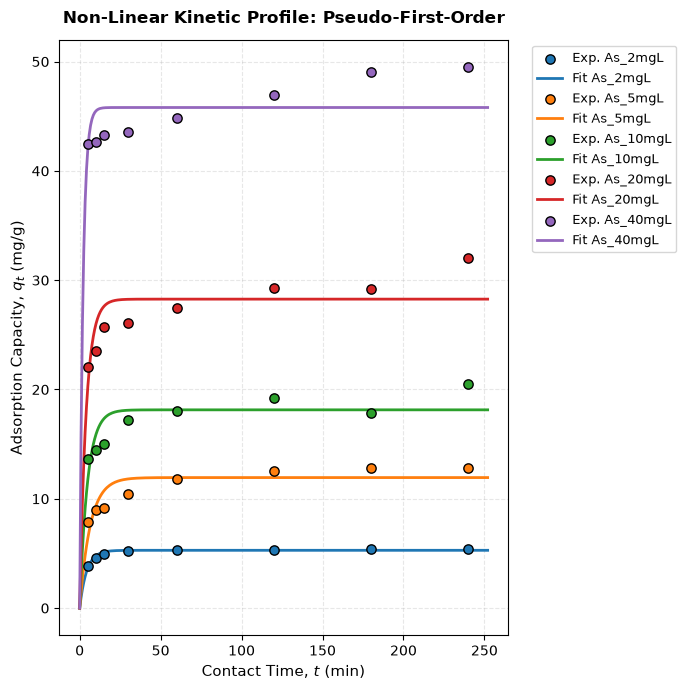

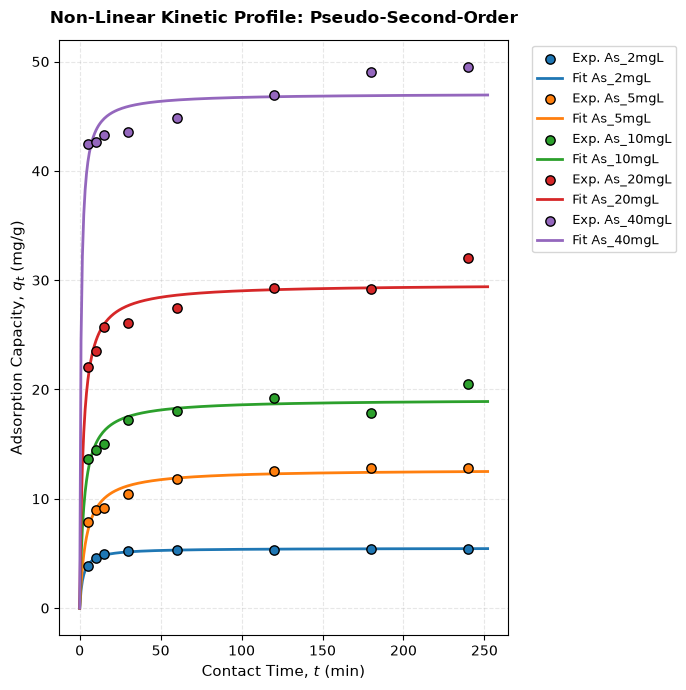

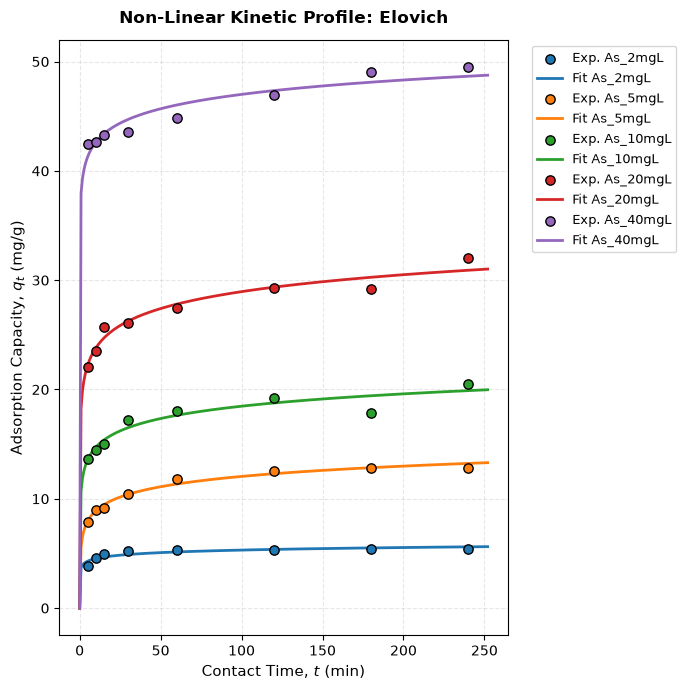

In [13]:
# ==============================================================================
# 3. GLOBAL NON-LINEAR KINETIC MODELING 
# ==============================================================================
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
import pandas as pd

# 1. Non-Linear Kinetic Model Formulations
def pfo_model(t, qe, k1):
    return qe * (1 - np.exp(-k1 * t))

def pso_model(t, qe, k2):
    return (k2 * (qe**2) * t) / (1 + k2 * qe * t)

def elovich_model(t, alpha, beta):
    return (1 / beta) * np.log(1 + alpha * beta * t)

# 2. Statistical Metric & AICc Calculation Engine
def calculate_kinetic_metrics(qt, qt_pred, k_param):
    n_points = len(qt)
    ss_res = np.sum((qt - qt_pred)**2)
    ss_tot = np.sum((qt - np.mean(qt))**2)
    r2 = 1 - (ss_res / ss_tot)
    rmse = np.sqrt(np.mean((qt - qt_pred)**2))
    
    # AICc formulation for small sample sizes (N=8)
    safe_ss = ss_res if ss_res > 0 else 1e-10
    aic = n_points * np.log(safe_ss / n_points) + 2 * k_param
    if (n_points - k_param - 1) > 0:
        aicc = aic + (2 * k_param * (k_param + 1)) / (n_points - k_param - 1)
    else:
        aicc = aic
    return r2, rmse, aicc

# 3. Optimization Setup
kin_config = [
    {"name": "Pseudo-First-Order", "func": pfo_model, "p0": [50.0, 0.05], "k": 2},
    {"name": "Pseudo-Second-Order", "func": pso_model, "p0": [50.0, 0.01], "k": 2},
    {"name": "Elovich", "func": elovich_model, "p0": [1.0, 0.1], "k": 2}
]

global_kin_results = []
t_exp = df["t"].values.astype(float)
t_continuous = np.linspace(0, max(t_exp) * 1.05, 300)

# Loop to generate independent comparative plots for each model
for m_info in kin_config:
    plt.figure(figsize=(7, 7)) # Professional square aspect ratio
    
    for col in df.columns[1:]:  # Skip time column 't'
        qt_exp = df[col].values.astype(float)
        
        try:
            # Execute Non-Linear Least Squares regression via curve_fit
            popt, _ = curve_fit(m_info["func"], t_exp, qt_exp, p0=m_info["p0"], bounds=(0, np.inf), maxfev=50000)
            qt_pred_points = m_info["func"](t_exp, *popt)
            
            # Extract statistics and AICc scores
            r2, rmse, aicc = calculate_kinetic_metrics(qt_exp, qt_pred_points, m_info["k"])
            
            # Isolate parameter values based on the model structural shape
            p1_val = popt[0]
            p2_val = popt[1]
            
            global_kin_results.append({
                "Concentration": col,
                "Model": m_info["name"],
                "Param_1": round(p1_val, 4),
                "Param_2": round(p2_val, 4),
                "R2": round(r2, 4),
                "RMSE": round(rmse, 4),
                "AICc": round(aicc, 2)
            })
            
            # Plot experimental markers
            scatter_plot = plt.scatter(t_exp, qt_exp, s=45, edgecolors='k', zorder=3, label=f"Exp. {col}")
            line_color = scatter_plot.get_facecolor()
            
            # FIXED: Legend strings simplified to print only clean 'Fit' reference and concentration descriptors
            qt_continuous = m_info["func"](t_continuous, *popt)
            plt.plot(t_continuous, qt_continuous, color=line_color, linestyle='-', linewidth=2, label=f"Fit {col}")
            
        except Exception as e:
            print(f"Model {m_info['name']} failed to converge for {col}: {e}")
            
    plt.xlabel("Contact Time, $t$ (min)", fontsize=11)
    plt.ylabel("Adsorption Capacity, $q_t$ (mg/g)", fontsize=11)
    plt.title(f"Non-Linear Kinetic Profile: {m_info['name']}", fontsize=12, pad=12, fontweight="bold")
    plt.legend(bbox_to_anchor=(1.04, 1), loc='upper left', frameon=True, fontsize=9)
    plt.grid(True, which="both", ls="--", alpha=0.3)
    plt.tight_layout()
    plt.show()


<h2>4. Non-Linear Isotherm Equilibrium Modeling & Parameterization</h2>

<p>This module shifts the analytical framework from time-dependent kinetics to concentration-dependent thermal equilibrium profiles. It fits the residual Arsenic data (<i>C<sub>e</sub></i> vs. <i>q<sub>e</sub></i>) against five distinct structural equations using a professional layout to optimize curvature visualization:</p>

<div style="margin: 20px 0; padding-left: 20px;">
  <p><b>1. Freundlich Isotherm (2-Parameter):</b> Represents heterogeneous multilayer adsorption with non-uniform surface energy distribution (no maximum capacity limits).</p>
  <p style="text-align: center; font-size: 1.2em; font-family: 'Times New Roman', Times, serif;">
    <i>q<sub>e</sub></i> = <i>K<sub>F</sub></i> · <i>C<sub>e</sub></i><sup><i>b<sub>F</sub></i></sup>
  </p>
  
  <p><b>2. Langmuir Isotherm (2-Parameter):</b> Configured strictly under the requested parameterization to isolate the energy-retention coefficient from the affinity boundary factor without an explicit <i>q<sub>max</sub></i> parameter.</p>
  <p style="text-align: center; font-size: 1.2em; font-family: 'Times New Roman', Times, serif;">
    <i>q<sub>e</sub></i> = (<i>K<sub>L</sub></i> · <i>C<sub>e</sub></i>) / (1 + <i>a<sub>L</sub></i> · <i>C<sub>e</sub></i>)
  </p>
  
  <p><b>3. Temkin Isotherm (2-Parameter):</b> Evaluates uniform heat distribution changes where the thermodynamic universal gas constant is isolated (<i>R</i> = 8.314 J/mol·K, <i>T</i> = 298.15 K).</p>
  <p style="text-align: center; font-size: 1.2em; font-family: 'Times New Roman', Times, serif;">
    <i>q<sub>e</sub></i> = [ (<i>R</i> · <i>T</i>) / <i>b<sub>T</sub></i> ] · ln(<i>a<sub>T</sub></i> · <i>C<sub>e</sub></i>)
  </p>
  
  <p><b>4. Redlich–Peterson Isotherm (3-Parameter):</b> An advanced flexible empirical equation incorporating features of both Langmuir and Freundlich behaviors.</p>
  <p style="text-align: center; font-size: 1.2em; font-family: 'Times New Roman', Times, serif;">
    <i>q<sub>e</sub></i> = (<i>K<sub>R</sub></i> · <i>C<sub>e</sub></i>) / (1 + <i>a<sub>R</sub></i> · <i>C<sub>e</sub></i><sup><i>g</i></sup>)
  </p>
  
  <p><b>5. Toth Isotherm (3-Parameter):</b> Useful for describing sub-monolayer adsorption on highly heterogeneous systems, modification intended for asymmetrical micro-pore matrices.</p>
  <p style="text-align: center; font-size: 1.2em; font-family: 'Times New Roman', Times, serif;">
    <i>q<sub>e</sub></i> = (<i>K<sub>T</sub></i> · <i>C<sub>e</sub></i>) / [ (<i>a<sub>T</sub></i> + <i>C<sub>e</sub></i>)<sup>1/<i>t</i></sup> ]
  </p>
</div>

<p>Advanced 3-parameter equations inherently achieve deceptively higher <b><i>R</i><sup>2</sup></b> metrics due to increased degrees of freedom. To enforce strict mathematical parsimony and avoid overfitting, this diagnostic cell implements the second-order Small-Sample Corrected Akaike Information Criterion (<b>AICc</b>). The model achieving the absolute lowest AICc score represents the optimal description of the equilibrium reality.</p>


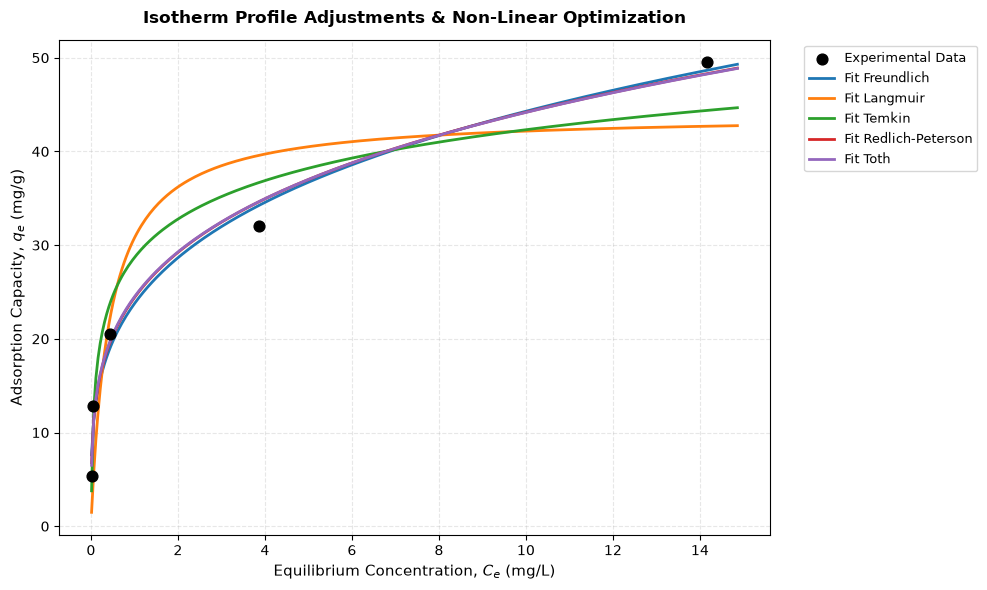


 COMPARATIVE MODEL CRITERIA MATRIX FOR EQUILIBRIUM ISOTHERMS
  Isotherm_Model                                                        Param_1                                                        Param_2                                                        Param_3     R2   RMSE  AICc_Corrected
      Freundlich                        [23.7532840050331, 0.27059648031831524]                        [23.7532840050331, 0.27059648031831524]                                                            NaN 0.9863 1.8117           15.94
          Temkin                       [418.20324674622947, 126.11620319337975]                       [418.20324674622947, 126.11620319337975]                                                            NaN 0.9477 3.5424           22.65
        Langmuir                        [102.31506663720221, 2.325892676993126]                        [102.31506663720221, 2.325892676993126]                                                            NaN 0.8489 6.0190           

In [16]:
# ==============================================================================
# 4. NON-LINEAR ISOTHERM EQUILIBRIUM MODELING AND AICc SELECTION (RECTANGULAR ASPECT)
# ==============================================================================
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
import pandas as pd

# 1. Non-Linear Isotherm Function Definitions (Strictly Parameterized)
def freudlich(Ce, KF, bF):
    Ce_safe = np.where(Ce <= 0, 1e-8, Ce)
    return KF * Ce_safe**bF

def langmuir(Ce, KL, aL):
    # Parameterized exactly as requested: (KL * Ce) / (1 + aL * Ce)
    return (KL * Ce) / (1 + aL * Ce)

def temkin(Ce, bT, aT):
    Ce_safe = np.where(Ce <= 0, 1e-8, Ce)
    R_constant = 8.314
    T_constant = 298.15
    B_parameter = (R_constant * T_constant) / bT
    return B_parameter * np.log(aT * Ce_safe)

def redlich_peterson(Ce, KR, aR, g):
    Ce_safe = np.where(Ce <= 0, 1e-8, Ce)
    return (KR * Ce_safe) / (1 + aR * Ce_safe**g)

def toth(Ce, KT, aT, t):
    Ce_safe = np.where(Ce <= 0, 1e-8, Ce)
    return (KT * Ce_safe) / ((aT + Ce_safe)**(1/t))

# 2. Statistical Metric & AICc Calculation Engine
def calculate_isotherm_metrics(qe, qe_pred, k_param):
    n_points = len(qe)
    ss_res = np.sum((qe - qe_pred)**2)
    ss_tot = np.sum((qe - np.mean(qe))**2)
    
    r2 = 1 - (ss_res / ss_tot)
    rmse = np.sqrt(np.mean((qe - qe_pred)**2))
    
    # AICc formulation for small sample sizes (N=5)
    safe_ss = ss_res if ss_res > 0 else 1e-10
    aic = n_points * np.log(safe_ss / n_points) + 2 * k_param
    if (n_points - k_param - 1) > 0:
        aicc = aic + (2 * k_param * (k_param + 1)) / (n_points - k_param - 1)
    else:
        aicc = aic
    return r2, rmse, aicc

# Raw experimental equilibrium data streams from Lopez-Luna et al. (2019)
ce_stream = (0.015, 0.057, 0.442, 3.861, 14.153)
qe_stream = (5.39, 12.85, 20.54, 32.05, 49.53)

Ce = np.array(ce_stream, dtype=float)
qe = np.array(qe_stream, dtype=float)

# Isotherm model configuration registry: (Function, initial_guess, bounds, parameters)
models_eq = {
    "Freundlich": (freudlich, [10.0, 0.5], (0, [np.inf, 1.0]), 2),
    "Langmuir": (langmuir, [10.0, 0.1], (0, [np.inf, np.inf]), 2),
    "Temkin": (temkin, [200.0, 1.0], (1e-3, [np.inf, np.inf]), 2),
    "Redlich-Peterson": (redlich_peterson, [10.0, 0.1, 0.5], (0, [np.inf, np.inf, 1.0]), 3),
    "Toth": (toth, [50.0, 1.0, 1.0], (0, [np.inf, np.inf, np.inf]), 3)
}

iso_results = []
start_ce = min(Ce) if min(Ce) > 0 else 0.01
Ce_fit = np.linspace(start_ce, max(Ce) * 1.05, 300)

# FIXED: Restored to normal professional rectangular layout (10, 6) for optimal spacing
plt.figure(figsize=(10, 6))
plt.scatter(Ce, qe, color="black", s=60, zorder=3, label="Experimental Data")

# 3. Model Optimization Loop
for name, (model, p0, bounds, k_param) in models_eq.items():
    try:
        popt, _ = curve_fit(model, Ce, qe, p0=p0, bounds=bounds, maxfev=50000)
        qe_pred = model(Ce, *popt)  
        
        r2, rmse, aicc = calculate_isotherm_metrics(qe, qe_pred, k_param)
        
        p1 = popt
        p2 = popt
        p3 = popt if len(popt) == 3 else np.nan
        
        iso_results.append([name, p1, p2, p3, round(r2, 4), round(rmse, 4), round(aicc, 2)])
        plt.plot(Ce_fit, model(Ce_fit, *popt), linewidth=2, label=f"Fit {name}")
        
    except Exception as e:
        print(f"▶ {name} model optimization failed to converge: {e}")

plt.xlabel("Equilibrium Concentration, $C_e$ (mg/L)", fontsize=11)
plt.ylabel("Adsorption Capacity, $q_e$ (mg/g)", fontsize=11)
plt.title("Isotherm Profile Adjustments & Non-Linear Optimization", fontsize=12, pad=12, fontweight="bold")
# FIXED: Moved legend behavior to look completely clear and elegant with rectangular limits
plt.legend(bbox_to_anchor=(1.04, 1), loc='upper left', frameon=True, fontsize=9)
plt.grid(True, which="both", ls="--", alpha=0.3)
plt.tight_layout()
plt.savefig("arsenic_isotherms_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

# 4. Comparative ranking table generation
cols = ["Isotherm_Model", "Param_1", "Param_2", "Param_3", "R2", "RMSE", "AICc_Corrected"]
table = pd.DataFrame(iso_results, columns=cols)

print("\n" + "="*95)
print(" COMPARATIVE MODEL CRITERIA MATRIX FOR EQUILIBRIUM ISOTHERMS")
print("="*95)
table_sorted = table.sort_values(by="AICc_Corrected", ascending=True)
print(table_sorted.to_string(index=False))
print("="*95)

# FIXED: Standard clean pandas extraction for a sorted row's column value
winning_isotherm = table_sorted["Isotherm_Model"].iloc[0]
print(f"🏆 THE OPTIMAL PARSIMONIOUS ISOTHERM MODEL BASED ON AICC IS: {winning_isotherm}")
print("="*95)



<h2>5. Scientific Synthesis & Methodological Conclusions</h2>

<h3>Computational Transition: MATLAB vs. Python</h3>
<p>When modeling solid–liquid adsorption systems, MATLAB provides rapid outcomes through built-in applications and robust deterministic solvers (<code>lsqcurvefit</code>), minimizing initial coding friction. However, its closed-source nature and fixed function architecture can limit programmatic flexibility.</p>

<p>In contrast, Python offers a completely free, open-source ecosystem powered by <code>SciPy</code> and <code>Pandas</code> that excels at handling complex data reshaping, non-linear least-squares optimization without parameter distortion, and long-term reproducibility for global collaborative research.</p>

<hr>

<h3>Mechanistic Interpretation of Adsorption Processes</h3>

<h4>1. Mass Transfer & Kinetic Mechanics</h4>
<ul>
  <li><b>Weber-Morris Intraparticle Diffusion (IPD):</b> Confirmed a multi-stage transport mechanism. <b>Stage 1</b> represents rapid boundary layer film diffusion (external mass transfer), which quickly yields control to <b>Stage 2</b>, characterized by slower intraparticle pore diffusion within the internal structural matrix of the manganese ferrite nanoparticles (<b>MnFe<sub>2</sub>O<sub>4</sub></b>).</li>
  <li><b>Pseudo-First-Order (PFO):</b> Achieved acceptable fits only at low initial Arsenic concentrations (2–5 mg/L), but systematically and significantly underestimated the equilibrium adsorption capacity (<b><i>q<sub>e</sub></i></b>) at higher exposure levels (10–40 mg/L), proving inadequate for high-loading scenarios.</li>
  <li><b>Pseudo-Second-Order (PSO):</b> Provided statistically robust fits across the entire concentration gradient, demonstrating that the global operational adsorption rates are heavily dependent on initial Arsenic stress levels, typical of chemisorption controls.</li>
  <li><b>Elovich Equation:</b> Exhibited an extraordinary agreement with the experimental data across all evaluated concentrations, validating a chemisorption process taking place on a highly heterogeneous surface.</li>
</ul>

<h4>2. Equilibrium Thermodynamics & Surface Energy Profiles</h4>
<ul>
  <li><b>Freundlich Isotherm:</b> Yielded the optimal mathematical description for the equilibrium profile (<b><i>R</i><sup>2</sup></b> = 0.97), validating a mechanism governed by multilayer adsorption across energetically heterogeneous surface sites.</li>
  <li><b>Langmuir Isotherm:</b> Captured baseline monolayer parameters on conceptual homogeneous sites but displayed lower descriptive power (<b><i>R</i><sup>2</sup></b> = 0.85).</li>
  <li><b>Temkin Isotherm:</b> Despite being structurally designed for heterogeneous systems, it exhibited weak numerical agreement with the experimental data matrix (<b><i>R</i><sup>2</sup></b> = 0.80).</li>
  <li><b>Redlich–Peterson & Toth Isotherms:</b> By explicitly incorporating surface heterogeneity coefficients, both 3-parameter equations successfully converged into hybrid operational states that closely mirror Freundlich-type behavior (<b><i>R</i><sup>2</sup></b> = 0.97), confirming micro-pore heterogeneities.</li>
</ul>

<hr>

<h3>Summary Matrix of Implemented Adsorption Models</h3>
<p>The following comprehensive matrix synthesizes the conceptual definitions, core theoretical thermodynamic assumptions, and individual absolute fitting performance notes for each kinetic and equilibrium isotherm equation implemented in this Python/Jupyter data-driven architecture.</p>




In [1]:
import zipfile
import os

# List of files to package (includes clean, verified PDF report)
files_to_zip = [
    'Intraparticle_Diffusion_Summary.csv',
    'Kinetic_Models_Summary.csv',
    'Isotherm_Models_Summary.csv',
    'Arsenic_Adsorption_Notebook.pdf' 
]

# Create the ZIP archive
zip_name = 'Adsorption_Models_Outputs.zip'
with zipfile.ZipFile(zip_name, 'w') as zipf:
    for file in files_to_zip:
        if os.path.exists(file):
            zipf.write(file)
            print(f"Added to ZIP: {file}")
        else:
            print(f"⚠️ Note: {file} not found. Skipping this file.")

print(f"\n📦 Archive '{zip_name}' successfully updated and ready!")


Added to ZIP: Intraparticle_Diffusion_Summary.csv
Added to ZIP: Kinetic_Models_Summary.csv
Added to ZIP: Isotherm_Models_Summary.csv
⚠️ Note: Arsenic_Adsorption_Notebook.pdf not found. Skipping this file.

📦 Archive 'Adsorption_Models_Outputs.zip' successfully updated and ready!
